# Predictive Maintenance of an Industrial Production Line

**Major Project:** ML-based framework for machine health monitoring, failure prediction and maintenance prioritization.

This notebook uses the uploaded **AI4I 2020 Predictive Maintenance Dataset** (`ai4i2020.csv`) as the primary dataset. The project workflow follows the proposed methodology: data collection → preprocessing → feature engineering → baseline modelling → Random Forest prediction → validation → maintenance prioritization.

**Target:** `Machine failure`

The dataset contains temperature, rotational speed, torque, tool wear and machine-failure information. The notebook is designed to run locally/Jupyter and can also be adapted for Kaggle by changing `DATA_PATH`.


In [1]:
# 1. Import libraries
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

RANDOM_STATE = 42
print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Load the input dataset

The uploaded file is expected at `/mnt/data/ai4i2020.csv` in this environment.

For Kaggle or another local Jupyter environment, replace `DATA_PATH` with the location of `ai4i2020.csv`.


In [2]:
# 2. Load dataset
DATA_PATH = "/kaggle/input/datasets/anirudhajayaprakash/ai4i2020/ai4i2020.csv"

# Portable fallback for local/Kaggle execution
if not os.path.exists(DATA_PATH):
    DATA_PATH = "ai4i2020.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset path: {DATA_PATH}")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())


Dataset path: /kaggle/input/datasets/anirudhajayaprakash/ai4i2020/ai4i2020.csv
Rows: 10,000
Columns: 14


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# 3. Basic dataset inspection
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())


Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Data types:


,dtype
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64



Missing values:


,missing_values
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0



Duplicate rows: 0


Target distribution:


,count
Machine failure,
0,9661
1,339



Target percentage:


,percentage
Machine failure,
0,96.61
1,3.39


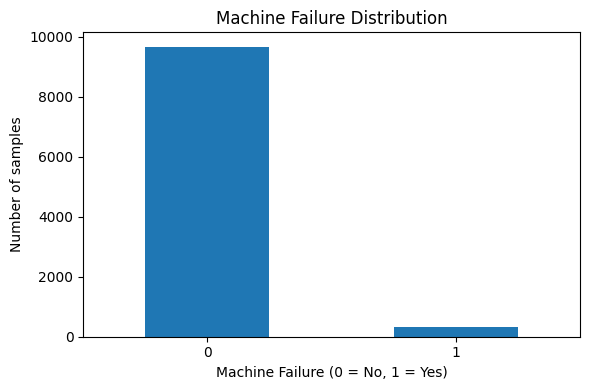

In [4]:
# 4. Target distribution
target = "Machine failure"

print("Target distribution:")
display(df[target].value_counts().rename_axis(target).to_frame("count"))

print("\nTarget percentage:")
display((df[target].value_counts(normalize=True) * 100).round(2).rename_axis(target).to_frame("percentage"))

plt.figure(figsize=(6, 4))
df[target].value_counts().sort_index().plot(kind="bar")
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No, 1 = Yes)")
plt.ylabel("Number of samples")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 3. Data preprocessing and feature selection

`UDI` and `Product ID` are identifiers and are excluded from modelling. `Machine failure` is the target.

The categorical `Type` feature is one-hot encoded. Numerical sensor/operational features are imputed and standardized for Logistic Regression. The same preprocessing pipeline is used consistently for both models.


In [5]:
# 5. Prepare features and target
drop_columns = ["UDI", "Product ID", target]

X = df.drop(columns=drop_columns)
y = df[target].astype(int)

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_features = X.select_dtypes(exclude=["object", "category"]).columns.tolist()

print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)
print("Number of input features before encoding:", X.shape[1])


Categorical features: ['Type']
Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Number of input features before encoding: 11


In [6]:
# 6. Train-test split
# Stratification preserves the failure/non-failure ratio in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(4))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(4))


Training samples: 8000
Testing samples : 2000

Training target distribution:
Machine failure
0    0.9661
1    0.0339
Name: proportion, dtype: float64

Testing target distribution:
Machine failure
0    0.966
1    0.034
Name: proportion, dtype: float64


In [7]:
# 7. Preprocessing pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


## 4. Logistic Regression baseline

Logistic Regression is used as the baseline classification model. It provides a simple reference against which the more flexible Random Forest model can be compared.


In [8]:
# 8. Logistic Regression baseline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

logistic_model.fit(X_train, y_train)

lr_pred = logistic_model.predict(X_test)
lr_prob = logistic_model.predict_proba(X_test)[:, 1]

lr_metrics = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test, lr_pred),
    "Precision": precision_score(y_test, lr_pred, zero_division=0),
    "Recall": recall_score(y_test, lr_pred, zero_division=0),
    "F1 Score": f1_score(y_test, lr_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, lr_prob)
}

pd.DataFrame([lr_metrics]).round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.999,1.0,0.9706,0.9851,0.9724


In [9]:
# 9. Logistic Regression classification report
print(classification_report(
    y_test, lr_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))


              precision    recall  f1-score   support

  No Failure       1.00      1.00      1.00      1932
     Failure       1.00      0.97      0.99        68

    accuracy                           1.00      2000
   macro avg       1.00      0.99      0.99      2000
weighted avg       1.00      1.00      1.00      2000



## 5. Random Forest predictive-maintenance model

Random Forest is used to model nonlinear relationships among temperature, process conditions, speed, torque and tool wear. Class weighting is enabled because machine failures are much less frequent than normal operating samples in this dataset.


In [10]:
# 10. Random Forest model
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

rf_metrics = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test, rf_pred),
    "Precision": precision_score(y_test, rf_pred, zero_division=0),
    "Recall": recall_score(y_test, rf_pred, zero_division=0),
    "F1 Score": f1_score(y_test, rf_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, rf_prob)
}

pd.DataFrame([rf_metrics]).round(4)


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.999,1.0,0.9706,0.9851,0.991


In [11]:
# 11. Random Forest classification report
print(classification_report(
    y_test, rf_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))


              precision    recall  f1-score   support

  No Failure       1.00      1.00      1.00      1932
     Failure       1.00      0.97      0.99        68

    accuracy                           1.00      2000
   macro avg       1.00      0.99      0.99      2000
weighted avg       1.00      1.00      1.00      2000



## 6. Confusion matrix

The confusion matrix shows:
- **True Negative:** correctly predicted healthy machine
- **False Positive:** healthy machine flagged for maintenance
- **False Negative:** failure missed by the model
- **True Positive:** correctly detected failure

For predictive maintenance, false negatives are particularly important because a missed failure can lead to unexpected downtime.


Confusion Matrix:
[[1932    0]
 [   2   66]]


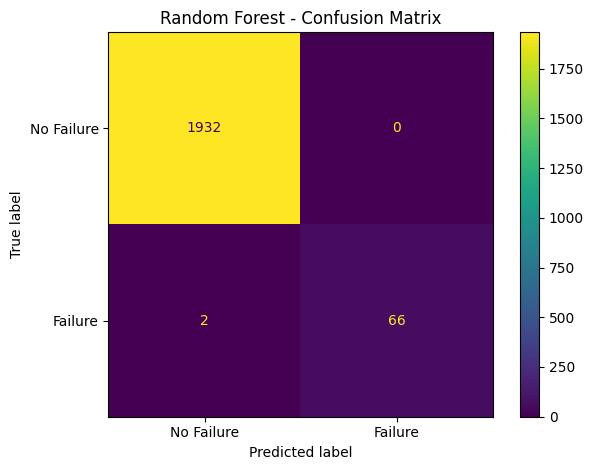

In [12]:
# 12. Confusion matrix - Random Forest
cm = confusion_matrix(y_test, rf_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)
disp.plot()
plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()


<Figure size 700x500 with 0 Axes>

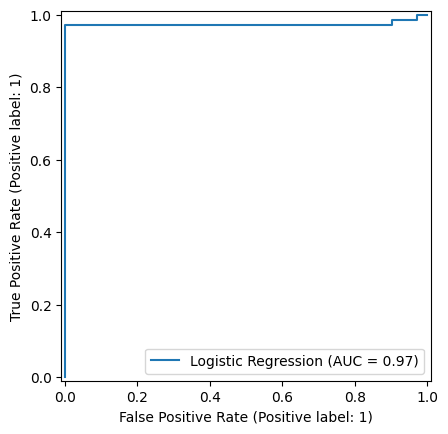

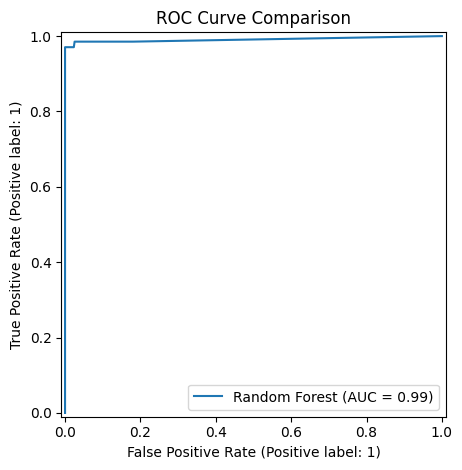

In [13]:
# 13. ROC curves
plt.figure(figsize=(7, 5))
RocCurveDisplay.from_predictions(y_test, lr_prob, name="Logistic Regression")
RocCurveDisplay.from_predictions(y_test, rf_prob, name="Random Forest")
plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.show()


## 7. Model comparison

The table below compares the baseline Logistic Regression model and the Random Forest model using accuracy, precision, recall, F1 and ROC-AUC.

Do not judge the model using accuracy alone because the target is imbalanced.


,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Model,,,,,
Logistic Regression,0.999,1.0,0.9706,0.9851,0.9724
Random Forest,0.999,1.0,0.9706,0.9851,0.9910


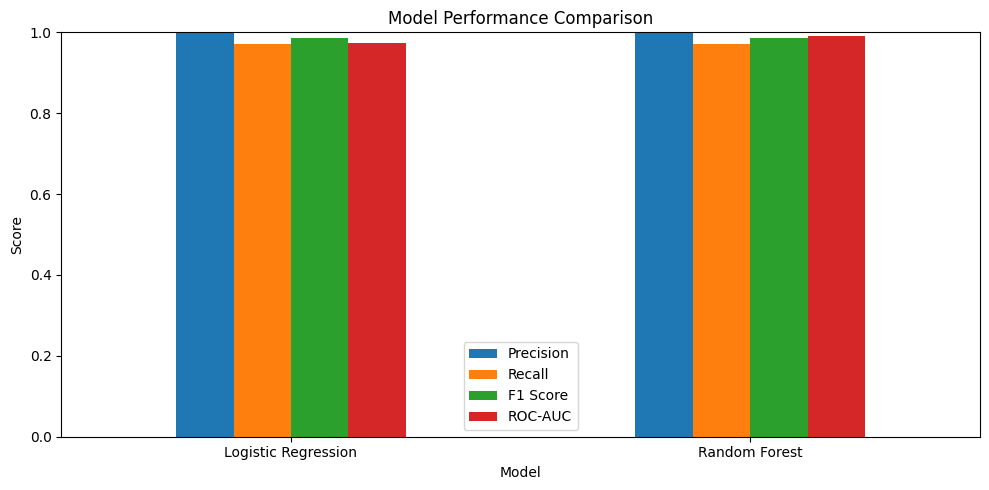

In [14]:
# 14. Compare models
comparison = pd.DataFrame([lr_metrics, rf_metrics]).set_index("Model")
display(comparison.round(4))

ax = comparison[["Precision", "Recall", "F1 Score", "ROC-AUC"]].plot(
    kind="bar", figsize=(10, 5)
)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 8. Feature importance from Random Forest

Feature importance is extracted after preprocessing. This provides an indication of which input variables contributed most to the Random Forest predictions.

Importance is model-specific and should not be interpreted as causal influence.


,Feature,Importance
3,num__Torque [Nm],0.172779
2,num__Rotational speed [rpm],0.168561
7,num__PWF,0.150339
6,num__HDF,0.120811
4,num__Tool wear [min],0.108257
8,num__OSF,0.102082
5,num__TWF,0.097438
0,num__Air temperature [K],0.042801
1,num__Process temperature [K],0.026790
11,cat__Type_L,0.004642


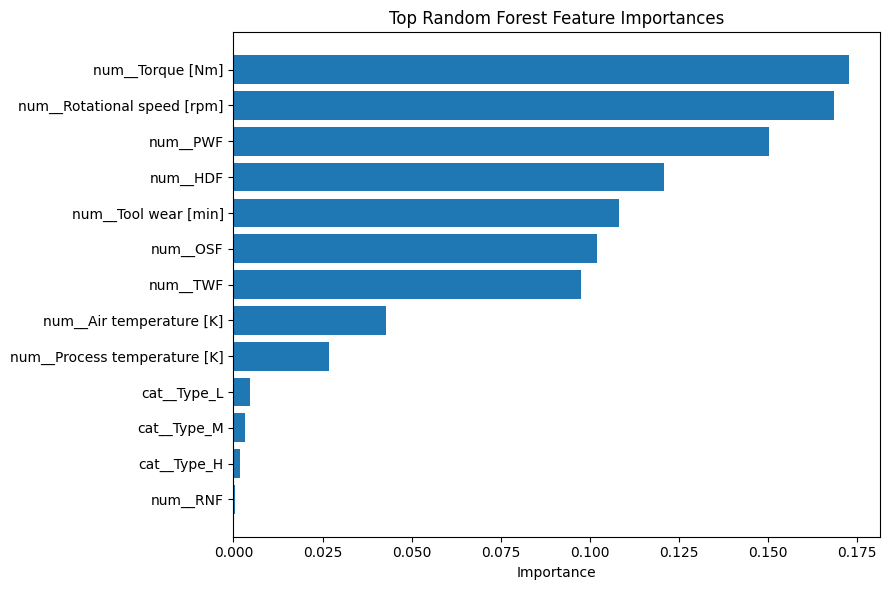

In [15]:
# 15. Random Forest feature importance
fitted_preprocessor = rf_model.named_steps["preprocessor"]
fitted_rf = rf_model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = fitted_rf.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(9, 6))
top_n = 15
plt.barh(
    importance_df.head(top_n)["Feature"][::-1],
    importance_df.head(top_n)["Importance"][::-1]
)
plt.title("Top Random Forest Feature Importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## 9. Machine-health / maintenance prioritization

The Random Forest probability of failure can be used as a **risk score** for maintenance prioritization.

The thresholds below are project-defined operational categories for demonstration:
- **Low risk:** probability < 0.30
- **Medium risk:** 0.30–0.60
- **High risk:** > 0.60

These thresholds should be calibrated with actual plant failure costs, maintenance capacity and domain-expert input before deployment.


In [16]:
# 16. Create maintenance-risk scores for the test set
risk_output = X_test.copy()
risk_output["Actual Failure"] = y_test.values
risk_output["Failure Risk"] = rf_prob

def risk_category(p):
    if p < 0.30:
        return "Low"
    elif p <= 0.60:
        return "Medium"
    return "High"

risk_output["Maintenance Priority"] = risk_output["Failure Risk"].apply(risk_category)

risk_output = risk_output.sort_values("Failure Risk", ascending=False)

display(
    risk_output[
        ["Actual Failure", "Failure Risk", "Maintenance Priority"]
    ].head(20).round(4)
)

print("\nMaintenance priority counts:")
display(risk_output["Maintenance Priority"].value_counts())


,Actual Failure,Failure Risk,Maintenance Priority
4661,1,0.9867,High
1391,1,0.9867,High
4495,1,0.9867,High
4270,1,0.9867,High
4170,1,0.9767,High
4179,1,0.9767,High
7011,1,0.9733,High
4080,1,0.9733,High
4081,1,0.9733,High
6078,1,0.9733,High



Maintenance priority counts:


Maintenance Priority
Low       1934
High        64
Medium       2
Name: count, dtype: int64

## 10. Predict failure risk for a new machine observation

Enter sensor/operating values using the same columns as the dataset. The trained Random Forest model returns a failure probability and maintenance-priority category.


In [17]:
# 17. Example: predict risk for a new machine observation
# Replace these values with real sensor readings before deployment.

sample_machine = pd.DataFrame([{
    "Type": "M",
    "Air temperature [K]": 298.5,
    "Process temperature [K]": 308.8,
    "Rotational speed [rpm]": 1500,
    "Torque [Nm]": 45.0,
    "Tool wear [min]": 120
}])

sample_probability = rf_model.predict_proba(sample_machine)[:, 1][0]
sample_prediction = int(rf_model.predict(sample_machine)[0])

print(f"Predicted failure class: {sample_prediction}")
print(f"Failure probability: {sample_probability:.4f}")
print(f"Maintenance priority: {risk_category(sample_probability)}")


ValueError: columns are missing: {'HDF', 'OSF', 'TWF', 'PWF', 'RNF'}

## 11. Save model results

The risk-ranked test-set predictions are saved as a CSV file so they can be used for further dashboarding or reporting.


In [ ]:
# 18. Export maintenance-risk results
OUTPUT_PATH = "maintenance_risk_predictions.csv"

risk_output.to_csv(OUTPUT_PATH, index=False)

print(f"Saved: {OUTPUT_PATH}")
print(f"Rows exported: {len(risk_output):,}")


## 12. Project conclusion

This notebook implements the initial predictive-maintenance pipeline:

1. Loads the AI4I 2020 production-machine dataset.
2. Performs data inspection and preprocessing.
3. Uses Logistic Regression as a baseline.
4. Trains a Random Forest failure-classification model.
5. Evaluates both models using Accuracy, Precision, Recall, F1 and ROC-AUC.
6. Generates a confusion matrix and ROC comparison.
7. Extracts Random Forest feature importance.
8. Converts predicted failure probability into maintenance-priority categories.
9. Exports risk-ranked predictions for downstream monitoring.

### Extension for the proposed project

The project proposal also considers vibration data, personalized machine/machine-family modelling, time-series/degradation models and optional Remaining Useful Life (RUL). Those extensions require suitable time-series or vibration datasets and should be added as separate modelling stages rather than being inferred from the AI4I classification labels.
